In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "02_E0.4_phan_bo_cong_suat_theo_gio_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:01:14 | INFO | Bắt đầu chạy 02_E0.4_phan_bo_cong_suat_theo_gio_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0001_02_E0.4_phan_bo_cong_suat_theo_gio_Han.log


# E0.4 – Phân bố công suất theo giờ

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.4 – Phân bố công suất theo giờ |
| **Mục đích** | Tách từ `02_eda.ipynb`: phần phân bố biến mục tiêu (mục 2). |
| **Đọc vào** | `data/processed/hourly_clean.csv` (do `01_cleaning` tạo) |
| **Ghi ra** | `figures/eda_figures/02_phan_bo_cong_suat.*` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv`) |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [3]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [4]:
MA_TN = "E0.4"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.4

## 2. Phân bố của biến mục tiêu `Global_active_power`
Xem hình dạng phân bố trước khi đi vào quy luật theo thời gian.

count    34157.0000
mean         1.0916
std          0.8977
min          0.1240
25%          0.3419
50%          0.8026
75%          1.5793
max          6.5605
Name: Global_active_power, dtype: float64
Độ lệch (skewness): 1.298


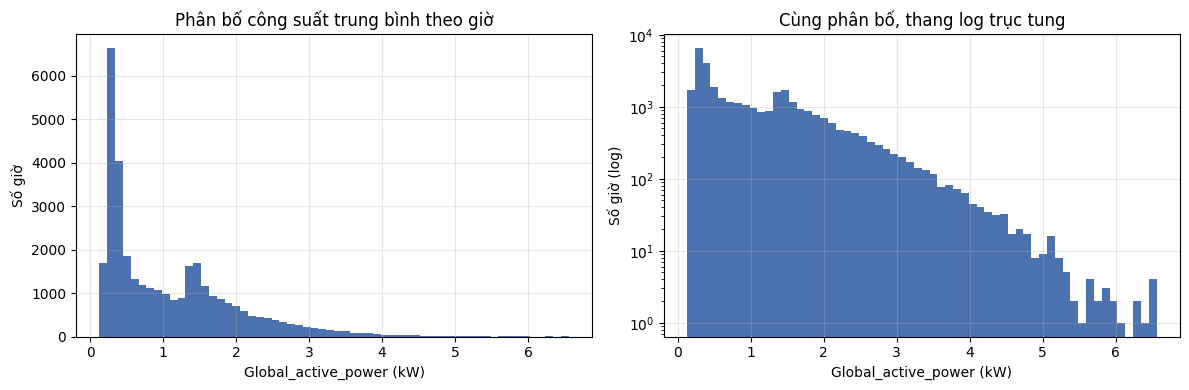

In [5]:
s = df[TARGET].dropna()
desc = s.describe()
skew = s.skew()
print(desc.round(4))
print("Độ lệch (skewness):", round(skew, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(s, bins=60, color="#4C72B0")
ax[0].set_title("Phân bố công suất trung bình theo giờ")
ax[0].set_xlabel("Global_active_power (kW)"); ax[0].set_ylabel("Số giờ")
ax[1].hist(s, bins=60, color="#4C72B0", log=True)
ax[1].set_title("Cùng phân bố, thang log trục tung")
ax[1].set_xlabel("Global_active_power (kW)"); ax[1].set_ylabel("Số giờ (log)")
plt.tight_layout()
save_fig("02_phan_bo_cong_suat")
plt.show()

add_note("Phân bố", f"Công suất trung bình theo giờ có trung bình {vn(s.mean())} kW, trung vị {vn(s.median())} kW, độ lệch chuẩn {vn(s.std())} kW; "
         f"giá trị nhỏ nhất {vn(s.min())} kW và lớn nhất {vn(s.max())} kW. Độ lệch (skewness) bằng {vn(skew, 2)}, "
         f"{'phân bố lệch phải: phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ tiêu thụ cao' if skew > 0.5 else 'phân bố không lệch rõ rệt'}.")

**Nhận xét:** Phân bố công suất theo giờ lệch phải rõ (skewness 1,30): trung bình 1,092 kW lớn hơn trung vị 0,803 kW. Phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ lên tới 6,561 kW. Vì vậy sai số của mô hình dễ bị kéo lên bởi các đỉnh hiếm này.

## Gợi ý nhận xét E0.4 (số tự điền)

In [6]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 00:01:15 | INFO | Gợi ý nhận xét E0.4 (số tự điền), lưu ở data/eda_E0.4_goi_y_nhan_xet.md:
- **[Phân bố]** Công suất trung bình theo giờ có trung bình 1,092 kW, trung vị 0,803 kW, độ lệch chuẩn 0,898 kW; giá trị nhỏ nhất 0,124 kW và lớn nhất 6,561 kW. Độ lệch (skewness) bằng 1,30, phân bố lệch phải: phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ tiêu thụ cao.


## Log lên W&B (minh chứng)

In [7]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = []
    HINH = ['02_phan_bo_cong_suat.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.4-Han-phan-bo-cong-suat-theo-gio", tags=["E0.4", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({"skew_theo_gio": float(skew), "trung_binh_kW": float(s.mean()), "trung_vi_kW": float(s.median())})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in notes[moc_note:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run btoer2q2


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000116-btoer2q2
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.4-Han-phan-bo-cong-suat-theo-gio


... (7 outputs left out)

wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 
wandb: Run summary:
wandb: skew_theo_gio 1.2978
wandb: trung_binh_kW 1.09164
wandb:   trung_vi_kW 0.8026
wandb: 


wandb: 🚀 View run ck-E0.4-Han-phan-bo-cong-suat-theo-gio at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/btoer2q2
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 2 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000116-btoer2q2/logs


## Nhật ký

- 01/11/2026 – Viết lần đầu trong notebook `02_eda.ipynb`. Commit `74a9949`.
- 07/11/2026 – Sửa `02_eda.ipynb`. Commit `9a1f293`, `910a450`.
- 13/11/2026 – Tách phần phân bố biến mục tiêu (mục 2) ra khỏi `02_eda.ipynb` thành notebook riêng `02_E0.4_phan_bo_cong_suat_theo_gio_Han.ipynb`, thêm ô ghi log. Commit `cdf1bfd` (lúc này notebook chưa chạy).
- 13/11/2026 – Lần chạy 20:11 trong VS Code bị treo sau ô đầu tiên (log chỉ có 1 dòng); chạy lại lúc 20:15 bằng `jupyter nbconvert`, có đủ output và log. Commit `0fc8474`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.